# 06.3. Empirical OOF Ensemble Blend

**Stage:** 06_ml (Task 4.3)  
**Inputs:** OOF MC probabilities, OOF XGBoost probabilities, feature table, config  
**Outputs:** `data/processed/ensemble_sweep_results.parquet`, `data/processed/ensemble_probabilities.parquet`  

This notebook evaluates Monte Carlo and XGBoost probability blends using only the common chronological OOF fixture population. It does not use in-sample probabilities, random splits, or a forced 50/50 blend.

In [1]:
# Load configuration and imports
%load_ext autoreload
%autoreload 2
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = Path.cwd()
while repo_root != repo_root.parent and not (repo_root / "src" / "config" / "loader.py").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root))

from src.config.loader import load_config
from src.ml.xgboost_model import POISSON_MC_FEATURES, get_feature_columns, train_xgboost
from src.ml.ensemble_blend import (
    align_oof_inputs,
    blend_probabilities,
    evaluate_probability_predictions,
    select_best_candidate,
    sweep_ensemble_weights,
    validate_probability_matrix,
)

config = load_config()
processed_dir = repo_root / "data" / "processed"
feature_table = pd.read_parquet(processed_dir / "feature_table.parquet")
mc_df = pd.read_parquet(processed_dir / "mc_probabilities.parquet")
full_xgb_df = pd.read_parquet(processed_dir / "xgboost_probabilities.parquet")
print(f"Feature table: {len(feature_table)} rows")
print(f"MC probabilities: {len(mc_df)} rows")
print(f"Persisted full XGBoost probabilities: {len(full_xgb_df)} rows")

Feature table: 760 rows
MC probabilities: 760 rows
Persisted full XGBoost probabilities: 760 rows


## Load and Validate OOF Probability Inputs

In [2]:
# Validate schemas, dates, target alignment, and OOF scope
feature_table["date"] = pd.to_datetime(feature_table["date"])
full_aligned = align_oof_inputs(mc_df, full_xgb_df, feature_table)
print(f"Common full-XGB OOF population: {len(full_aligned)} fixtures")
print(f"Date range: {full_aligned['date'].min()} to {full_aligned['date'].max()}")
assert len(full_aligned) == 560, f"Expected 560 OOF fixtures, got {len(full_aligned)}"

context_columns = [column for column in get_feature_columns(feature_table) if column not in POISSON_MC_FEATURES]
context_results = train_xgboost(
    features=feature_table[context_columns],
    target=feature_table["target_encoded"],
    config=config,
)
context_xgb_df = feature_table[["fixture_id", "date", "target_encoded"]].copy()
context_oof = context_results["oof_probabilities"]
context_xgb_df["xgb_prob_home_win"] = context_oof[:, 0]
context_xgb_df["xgb_prob_draw"] = context_oof[:, 1]
context_xgb_df["xgb_prob_away_win"] = context_oof[:, 2]
context_aligned = align_oof_inputs(mc_df, context_xgb_df, feature_table)
assert set(context_aligned["fixture_id"]) == set(full_aligned["fixture_id"])

for label, frame in [("MC", full_aligned), ("full XGB", full_aligned), ("context XGB", context_aligned)]:
    for prefix in ("mc", "xgb"):
        matrix = frame[[f"{prefix}_prob_home_win", f"{prefix}_prob_draw", f"{prefix}_prob_away_win"]].to_numpy()
        normalized = validate_probability_matrix(matrix)
        print(f"{label} {prefix} max row-sum error: {np.max(np.abs(normalized.sum(axis=1) - 1.0)):.3e}")

Common full-XGB OOF population: 560 fixtures
Date range: 2025-01-14 00:00:00 to 2026-05-24 00:00:00
MC mc max row-sum error: 0.000e+00
MC xgb max row-sum error: 0.000e+00
full XGB mc max row-sum error: 0.000e+00
full XGB xgb max row-sum error: 0.000e+00
context XGB mc max row-sum error: 0.000e+00
context XGB xgb max row-sum error: 0.000e+00


## Baseline Model Comparison

In [3]:
# Compare MC-only, full-XGB-only, and context-XGB-only on the same OOF rows
target = full_aligned["target_encoded"].to_numpy(dtype=int)
mc_probs = full_aligned[["mc_prob_home_win", "mc_prob_draw", "mc_prob_away_win"]].to_numpy()
full_xgb_probs = full_aligned[["xgb_prob_home_win", "xgb_prob_draw", "xgb_prob_away_win"]].to_numpy()
context_xgb_probs = context_aligned[["xgb_prob_home_win", "xgb_prob_draw", "xgb_prob_away_win"]].to_numpy()
baseline_rows = []
for candidate, probabilities in [("mc_only", mc_probs), ("full_xgb_only", full_xgb_probs), ("context_only", context_xgb_probs)]:
    baseline_rows.append({"candidate": candidate, "xgb_weight": float(candidate != "mc_only"), "mc_weight": float(candidate == "mc_only"), "oof_fixture_count": len(target), **evaluate_probability_predictions(probabilities, target)})
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results)

,candidate,xgb_weight,mc_weight,oof_fixture_count,accuracy,log_loss,brier_score
0,mc_only,0.0,1.0,560,0.475000,1.098442,0.660588
1,full_xgb_only,1.0,0.0,560,0.517857,1.029115,0.615997
2,context_only,1.0,0.0,560,0.500000,1.028023,0.615730


## Full XGBoost Ensemble Sweep

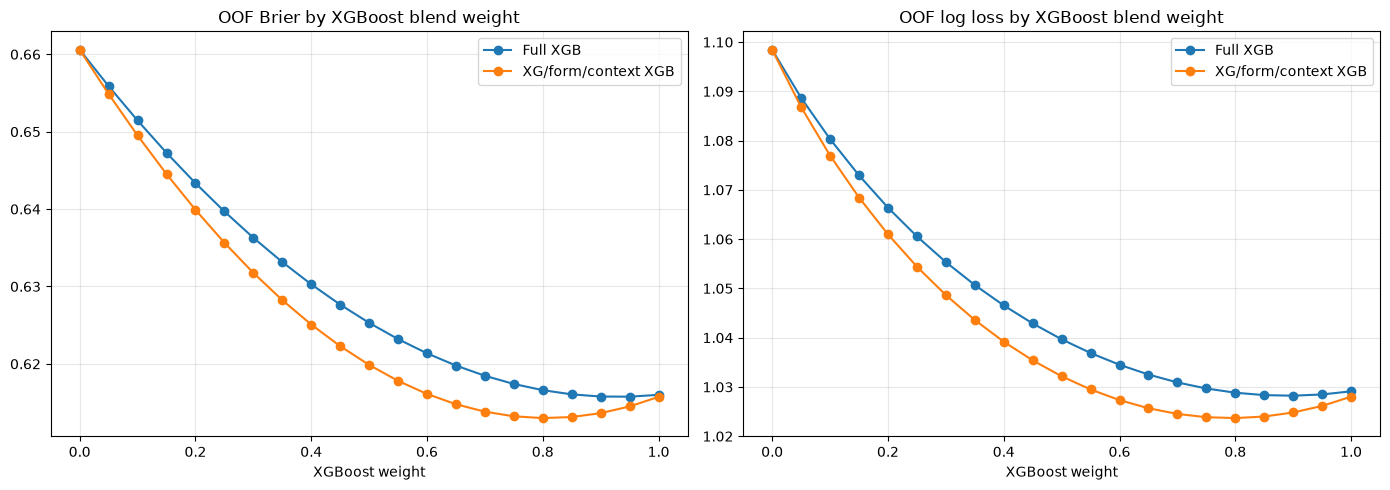

In [4]:
grid = config["ml"]["ensemble_grid"]
weights = [float(weight) for weight in grid["candidate_weights"]]
full_sweep = sweep_ensemble_weights(mc_probs, full_xgb_probs, target, weights, candidate="blend_full")
context_sweep = sweep_ensemble_weights(mc_probs, context_xgb_probs, target, weights, candidate="blend_context")

figure, axes = plt.subplots(1, 2, figsize=(14, 5))
for frame, label in [(full_sweep, "Full XGB"), (context_sweep, "XG/form/context XGB")]:
    axes[0].plot(frame["xgb_weight"], frame["brier_score"], marker="o", label=label)
    axes[1].plot(frame["xgb_weight"], frame["log_loss"], marker="o", label=label)
axes[0].set_title("OOF Brier by XGBoost blend weight")
axes[1].set_title("OOF log loss by XGBoost blend weight")
for axis in axes:
    axis.set_xlabel("XGBoost weight")
    axis.grid(alpha=0.3)
    axis.legend()
figure.tight_layout()
plt.show()

## XG/Form/Context Ensemble Sweep

In [5]:
# Candidate selection uses Brier, then log loss, then simplicity.
candidates = pd.concat([baseline_results, full_sweep, context_sweep], ignore_index=True)
primary_metric = grid["primary_metric"]
tie_break_metric = grid["tie_break_metric"]
selected = select_best_candidate(candidates, primary_metric, tie_break_metric, float(grid["tolerance"]))
candidates["is_selected"] = (candidates.index == selected.name)
print("## Candidate Selection")
display(candidates.sort_values([primary_metric, tie_break_metric]))
print(f"Selected candidate: {selected['candidate']} at XGBoost weight {selected['xgb_weight']:.2f}")
print("No blend is forced; endpoint weights remain valid candidates.")

## Candidate Selection


,candidate,xgb_weight,mc_weight,oof_fixture_count,accuracy,log_loss,brier_score,is_selected
40,blend_context,0.80,0.20,560,0.507143,1.023682,0.612993,True
41,blend_context,0.85,0.15,560,0.503571,1.023998,0.613129,False
39,blend_context,0.75,0.25,560,0.510714,1.023858,0.613224,False
42,blend_context,0.90,0.10,560,0.508929,1.024817,0.613630,False
38,blend_context,0.70,0.30,560,0.501786,1.024524,0.613820,False
43,blend_context,0.95,0.05,560,0.498214,1.026151,0.614497,False
37,blend_context,0.65,0.35,560,0.507143,1.025681,0.614782,False
2,context_only,1.00,0.00,560,0.500000,1.028023,0.615730,False
44,blend_context,1.00,0.00,560,0.500000,1.028023,0.615730,False
22,blend_full,0.95,0.05,560,0.519643,1.028479,0.615758,False


Selected candidate: blend_context at XGBoost weight 0.80
No blend is forced; endpoint weights remain valid candidates.


In [8]:
display(candidates)

,candidate,xgb_weight,mc_weight,oof_fixture_count,accuracy,log_loss,brier_score,is_selected
0,mc_only,0.00,1.00,560,0.475000,1.098442,0.660588,False
1,full_xgb_only,1.00,0.00,560,0.517857,1.029115,0.615997,False
2,context_only,1.00,0.00,560,0.500000,1.028023,0.615730,False
3,blend_full,0.00,1.00,560,0.475000,1.098442,0.660588,False
4,blend_full,0.05,0.95,560,0.475000,1.088692,0.655890,False
5,blend_full,0.10,0.90,560,0.482143,1.080313,0.651452,False
6,blend_full,0.15,0.85,560,0.485714,1.072946,0.647273,False
7,blend_full,0.20,0.80,560,0.489286,1.066403,0.643355,False
8,blend_full,0.25,0.75,560,0.496429,1.060565,0.639696,False
9,blend_full,0.30,0.70,560,0.503571,1.055349,0.636297,False


## Save Selected OOF Ensemble

In [6]:
# Persist the sweep and selected OOF-only probability artifact
sweep_path = processed_dir / "ensemble_sweep_results.parquet"
candidates.to_parquet(sweep_path, index=False)
selected_candidate = str(selected["candidate"])
selected_weight = float(selected["xgb_weight"])
selected_source = context_xgb_probs if selected_candidate in {"context_only", "blend_context"} else full_xgb_probs
selected_probabilities = blend_probabilities(mc_probs, selected_source, selected_weight)
ensemble_output = full_aligned[["fixture_id", "date", "target_encoded"]].copy()
ensemble_output["ensemble_prob_home_win"] = selected_probabilities[:, 0]
ensemble_output["ensemble_prob_draw"] = selected_probabilities[:, 1]
ensemble_output["ensemble_prob_away_win"] = selected_probabilities[:, 2]
ensemble_output["selected_candidate"] = selected_candidate
ensemble_output["selected_xgb_weight"] = selected_weight
ensemble_output["selected_mc_weight"] = 1.0 - selected_weight
ensemble_path = processed_dir / "ensemble_probabilities.parquet"
ensemble_output.to_parquet(ensemble_path, index=False)
assert np.allclose(selected_probabilities.sum(axis=1), 1.0, atol=1e-12)
print(f"Saved sweep: {sweep_path}")
print(f"Saved selected OOF ensemble ({len(ensemble_output)} rows): {ensemble_path}")
display(ensemble_output.head())

Saved sweep: /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/ensemble_sweep_results.parquet
Saved selected OOF ensemble (560 rows): /Users/mac/Documents/Projects/SportsBettingPoisson+ML/data/processed/ensemble_probabilities.parquet


,fixture_id,date,target_encoded,ensemble_prob_home_win,ensemble_prob_draw,ensemble_prob_away_win,selected_candidate,selected_xgb_weight,selected_mc_weight
0,118f8df8,2025-01-14,1,0.354713,0.296845,0.348443,blend_context,0.8,0.2
1,c6168c73,2025-01-14,0,0.193326,0.217778,0.588896,blend_context,0.8,0.2
2,fff671a9,2025-01-14,1,0.269103,0.230103,0.500794,blend_context,0.8,0.2
3,3e70b855,2025-01-15,2,0.364551,0.274509,0.360940,blend_context,0.8,0.2
4,535d70d7,2025-01-15,0,0.593596,0.263377,0.143027,blend_context,0.8,0.2
